In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [2]:
df = pd.read_csv("BlackFriday.csv")

# Display first five rows
display(df.head())

# Dataset information
print("Dataset Shape:", df.shape)
print("\nDataset Information:")
df.info()

# Statistical summary
display(df.describe())

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

,User_ID,Product_ID,Gender,Age,Occupation,City_Category,Stay_In_Current_City_Years,Marital_Status,Product_Category_1,Product_Category_2,Product_Category_3,Purchase
0,1000001,P00069042,F,0-17,10,A,2,0,3,NaN,NaN,8370
1,1000001,P00248942,F,0-17,10,A,2,0,1,6.0,14.0,15200
2,1000001,P00087842,F,0-17,10,A,2,0,12,NaN,NaN,1422
3,1000001,P00085442,F,0-17,10,A,2,0,12,14.0,NaN,1057
4,1000002,P00285442,M,55+,16,C,4+,0,8,NaN,NaN,7969


Dataset Shape: (537577, 12)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 537577 entries, 0 to 537576
Data columns (total 12 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   User_ID                     537577 non-null  int64  
 1   Product_ID                  537577 non-null  str    
 2   Gender                      537577 non-null  str    
 3   Age                         537577 non-null  str    
 4   Occupation                  537577 non-null  int64  
 5   City_Category               537577 non-null  str    
 6   Stay_In_Current_City_Years  537577 non-null  str    
 7   Marital_Status              537577 non-null  int64  
 8   Product_Category_1          537577 non-null  int64  
 9   Product_Category_2          370591 non-null  float64
 10  Product_Category_3          164278 non-null  float64
 11  Purchase                    537577 non-null  int64  
dtypes: float64(2), int64(5), str(5)
m

,User_ID,Occupation,Marital_Status,Product_Category_1,Product_Category_2,Product_Category_3,Purchase
count,5.375770e+05,537577.00000,537577.000000,537577.000000,370591.000000,164278.000000,537577.000000
mean,1.002992e+06,8.08271,0.408797,5.295546,9.842144,12.669840,9333.859853
std,1.714393e+03,6.52412,0.491612,3.750701,5.087259,4.124341,4981.022133
min,1.000001e+06,0.00000,0.000000,1.000000,2.000000,3.000000,185.000000
25%,1.001495e+06,2.00000,0.000000,1.000000,5.000000,9.000000,5866.000000
50%,1.003031e+06,7.00000,0.000000,5.000000,9.000000,14.000000,8062.000000
75%,1.004417e+06,14.00000,1.000000,8.000000,15.000000,16.000000,12073.000000
max,1.006040e+06,20.00000,1.000000,18.000000,18.000000,18.000000,23961.000000



Missing Values:
User_ID                            0
Product_ID                         0
Gender                             0
Age                                0
Occupation                         0
City_Category                      0
Stay_In_Current_City_Years         0
Marital_Status                     0
Product_Category_1                 0
Product_Category_2            166986
Product_Category_3            373299
Purchase                           0
dtype: int64


In [3]:
# Create a copy of the dataset
data = df.copy()

# Fill missing product categories
data['Product_Category_2'] = (
    data['Product_Category_2'].fillna(-1)
)

data['Product_Category_3'] = (
    data['Product_Category_3'].fillna(-1)
)

# Convert numerical category codes into categorical values
categorical_columns = [
    'Gender',
    'Age',
    'Occupation',
    'City_Category',
    'Stay_In_Current_City_Years',
    'Marital_Status',
    'Product_Category_1',
    'Product_Category_2',
    'Product_Category_3'
]

for col in categorical_columns:
    data[col] = data[col].astype(str)

# Remove identifier columns
data = data.drop(['User_ID', 'Product_ID'], axis=1)

print("Preprocessing completed.")
display(data.head())

Preprocessing completed.


,Gender,Age,Occupation,City_Category,Stay_In_Current_City_Years,Marital_Status,Product_Category_1,Product_Category_2,Product_Category_3,Purchase
0,F,0-17,10,A,2,0,3,-1.0,-1.0,8370
1,F,0-17,10,A,2,0,1,6.0,14.0,15200
2,F,0-17,10,A,2,0,12,-1.0,-1.0,1422
3,F,0-17,10,A,2,0,12,14.0,-1.0,1057
4,M,55+,16,C,4+,0,8,-1.0,-1.0,7969


In [4]:
# Create three purchase categories
data['Purchase_Level'] = pd.qcut(
    data['Purchase'],
    q=3,
    labels=['Low', 'Medium', 'High']
)

# Check class distribution
print(data['Purchase_Level'].value_counts())

# Display purchase category boundaries
print("\nPurchase Category Boundaries:")
print(pd.qcut(df['Purchase'], q=3).value_counts().sort_index())

Purchase_Level
Low       179342
High      179176
Medium    179059
Name: count, dtype: int64

Purchase Category Boundaries:
Purchase
(184.999, 6933.0]     179342
(6933.0, 10099.0]     179059
(10099.0, 23961.0]    179176
Name: count, dtype: int64


In [5]:
# Input features
X = data.drop(['Purchase', 'Purchase_Level'], axis=1)

# Target variable
y = data['Purchase_Level']

# Convert categorical features into numerical features
X = pd.get_dummies(X, drop_first=False, dtype='int8')

print("Input Features Shape:", X.shape)
print("Target Shape:", y.shape)

Input Features Shape: (537577, 92)
Target Shape: (537577,)


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (430061, 92)
Testing Features: (107516, 92)
Training Target: (430061,)
Testing Target: (107516,)


In [7]:
# Create ID3-style decision tree
id3_model = DecisionTreeClassifier(
    criterion='entropy',
    max_depth=10,
    min_samples_leaf=20,
    random_state=42
)

# Train the model
id3_model.fit(X_train, y_train)

# Make predictions
y_pred_id3 = id3_model.predict(X_test)

# Evaluate the model
print("DECISION TREE USING ID3 (ENTROPY)")
print("----------------------------------")

print("Accuracy:",
      accuracy_score(y_test, y_pred_id3))

print("Precision:",
      precision_score(y_test, y_pred_id3,
                      average='weighted', zero_division=0))

print("Recall:",
      recall_score(y_test, y_pred_id3,
                   average='weighted', zero_division=0))

print("F1 Score:",
      f1_score(y_test, y_pred_id3,
               average='weighted', zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_id3))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_id3,
                            zero_division=0))

DECISION TREE USING ID3 (ENTROPY)
----------------------------------
Accuracy: 0.7034952937237249
Precision: 0.6914485075509533
Recall: 0.7034952937237249
F1 Score: 0.6907530813064815

Confusion Matrix:
[[35788    40     7]
 [ 3460 20213 12196]
 [ 6488  9688 19636]]

Classification Report:
              precision    recall  f1-score   support

        High       0.78      1.00      0.88     35835
         Low       0.68      0.56      0.61     35869
      Medium       0.62      0.55      0.58     35812

    accuracy                           0.70    107516
   macro avg       0.69      0.70      0.69    107516
weighted avg       0.69      0.70      0.69    107516



In [8]:
# Create Gini-based decision tree
gini_model = DecisionTreeClassifier(
    criterion='gini',
    max_depth=10,
    min_samples_leaf=20,
    random_state=42
)

# Train the model
gini_model.fit(X_train, y_train)

# Make predictions
y_pred_gini = gini_model.predict(X_test)

# Evaluate the model
print("DECISION TREE USING GINI INDEX")
print("--------------------------------")

print("Accuracy:",
      accuracy_score(y_test, y_pred_gini))

print("Precision:",
      precision_score(y_test, y_pred_gini,
                      average='weighted', zero_division=0))

print("Recall:",
      recall_score(y_test, y_pred_gini,
                   average='weighted', zero_division=0))

print("F1 Score:",
      f1_score(y_test, y_pred_gini,
               average='weighted', zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_gini))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_gini,
                            zero_division=0))

DECISION TREE USING GINI INDEX
--------------------------------
Accuracy: 0.7032348673685777
Precision: 0.6922114090297607
Recall: 0.7032348673685777
F1 Score: 0.6905483744898514

Confusion Matrix:
[[35779    49     7]
 [ 3449 19579 12841]
 [ 6481  9080 20251]]

Classification Report:
              precision    recall  f1-score   support

        High       0.78      1.00      0.88     35835
         Low       0.68      0.55      0.61     35869
      Medium       0.61      0.57      0.59     35812

    accuracy                           0.70    107516
   macro avg       0.69      0.70      0.69    107516
weighted avg       0.69      0.70      0.69    107516



In [9]:
comparison = pd.DataFrame({

    'Model': [
        'ID3 (Entropy)',
        'Gini Index'
    ],

    'Accuracy': [
        accuracy_score(y_test, y_pred_id3),
        accuracy_score(y_test, y_pred_gini)
    ],

    'Precision': [
        precision_score(y_test, y_pred_id3,
                        average='weighted', zero_division=0),
        precision_score(y_test, y_pred_gini,
                        average='weighted', zero_division=0)
    ],

    'Recall': [
        recall_score(y_test, y_pred_id3,
                     average='weighted', zero_division=0),
        recall_score(y_test, y_pred_gini,
                     average='weighted', zero_division=0)
    ],

    'F1 Score': [
        f1_score(y_test, y_pred_id3,
                 average='weighted', zero_division=0),
        f1_score(y_test, y_pred_gini,
                 average='weighted', zero_division=0)
    ]

})

display(comparison)

,Model,Accuracy,Precision,Recall,F1 Score
0,ID3 (Entropy),0.703495,0.691449,0.703495,0.690753
1,Gini Index,0.703235,0.692211,0.703235,0.690548


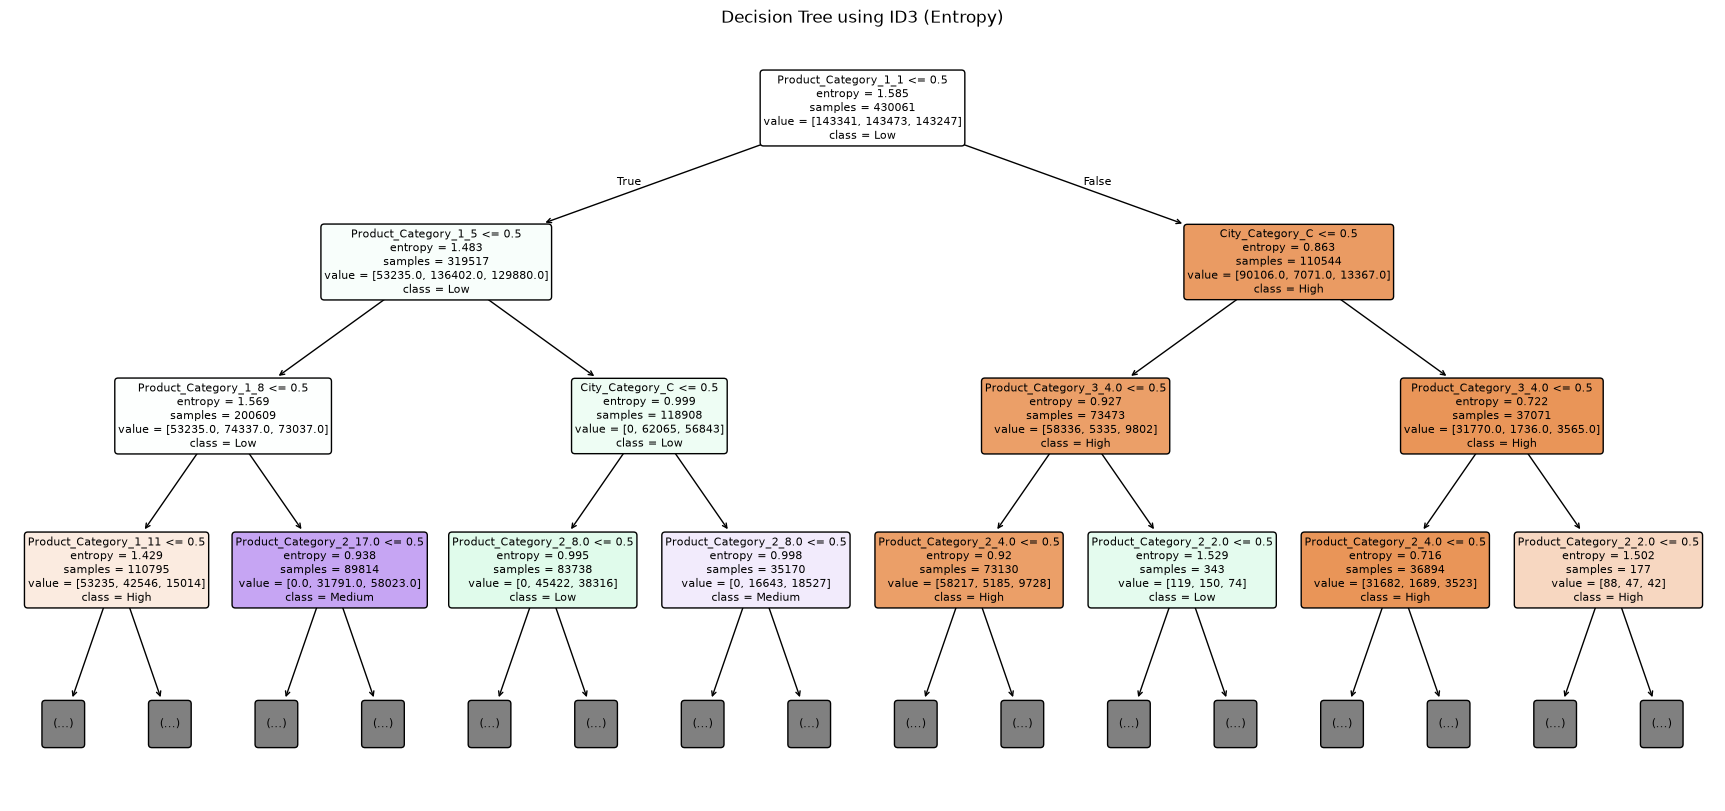

In [10]:
plt.figure(figsize=(22, 10))

plot_tree(
    id3_model,
    feature_names=X.columns,
    class_names=[str(c) for c in id3_model.classes_],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)

plt.title("Decision Tree using ID3 (Entropy)")
plt.show()

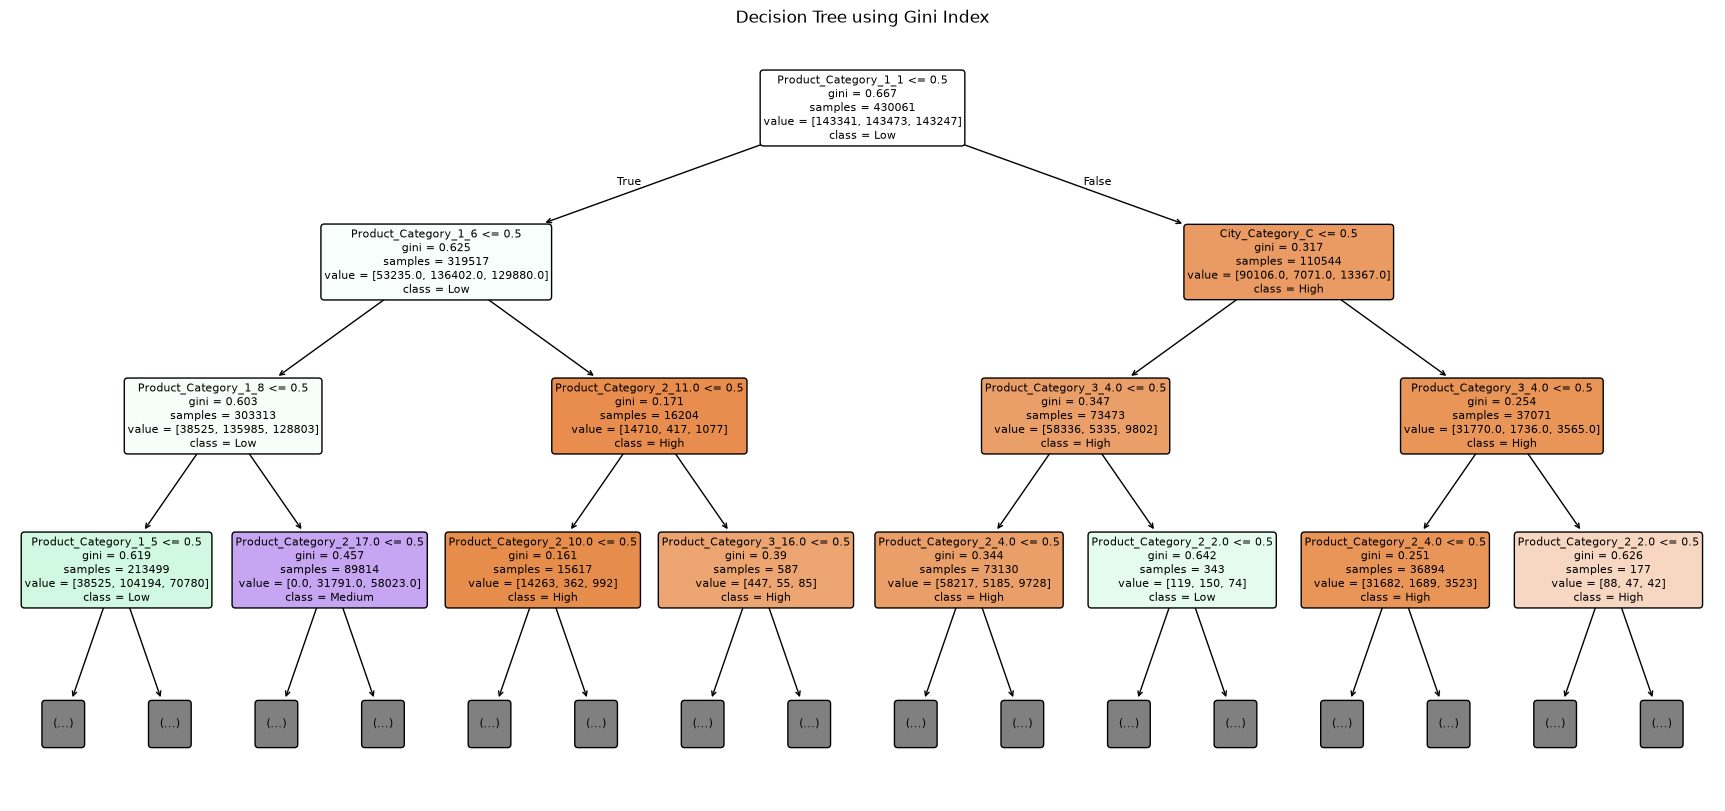

In [11]:
plt.figure(figsize=(22, 10))

plot_tree(
    gini_model,
    feature_names=X.columns,
    class_names=[str(c) for c in gini_model.classes_],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)

plt.title("Decision Tree using Gini Index")
plt.show()

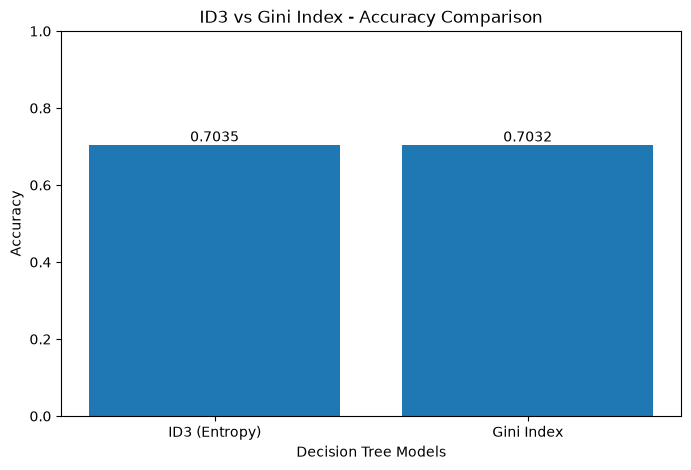

In [12]:
plt.figure(figsize=(8, 5))

models = ['ID3 (Entropy)', 'Gini Index']

accuracies = [
    accuracy_score(y_test, y_pred_id3),
    accuracy_score(y_test, y_pred_gini)
]

plt.bar(models, accuracies)

plt.title("ID3 vs Gini Index - Accuracy Comparison")
plt.xlabel("Decision Tree Models")
plt.ylabel("Accuracy")
plt.ylim(0, 1)

for i, value in enumerate(accuracies):
    plt.text(i, value + 0.01, f'{value:.4f}', ha='center')

plt.show()